# Project 12: Physics-Informed Neural Networks (PINN)

This project implements a Physics-Informed Neural Network using NeuroGebra's `PINN` module.
We train a neural network to solve two canonical differential equations:
1. 1D Damped Harmonic Oscillator: $m \frac{d^2 u}{dt^2} + c \frac{du}{dt} + k u = 0$
2. 1D Burgers' Equation: $\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} - \nu \frac{\partial^2 u}{\partial x^2} = 0$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neurogebra.science import PINN

np.random.seed(42)
print('[INFO] Scientific ML / PINN suite loaded.')


[INFO] Scientific ML / PINN suite loaded.


In [2]:
# 1. Setup Damped Harmonic Oscillator Problem
# Physical parameters: m=1.0, c=0.4, k=4.0 (underdamped)
m, c, k = 1.0, 0.4, 4.0
omega_0 = np.sqrt(k / m)
zeta = c / (2.0 * np.sqrt(m * k))
omega_d = omega_0 * np.sqrt(1.0 - zeta**2)

# Exact analytical solution: u(t) = exp(-zeta * omega_0 * t) * cos(omega_d * t)
t_domain = np.linspace(0, 5, 200).reshape(-1, 1)
u_exact = np.exp(-zeta * omega_0 * t_domain) * np.cos(omega_d * t_domain)

# Few initial condition / boundary data points
t_data = np.array([[0.0], [0.2], [0.4]])
u_data = np.exp(-zeta * omega_0 * t_data) * np.cos(omega_d * t_data)

# Domain collocation points for physics loss
t_colloc = np.linspace(0, 5, 80).reshape(-1, 1)
print(f'[INFO] Boundary samples: {len(t_data)}, Collocation points: {len(t_colloc)}')


[INFO] Boundary samples: 3, Collocation points: 80


In [3]:
# 2. Initialize and Train PINN
pinn = PINN(layer_sizes=[1, 32, 32, 1], activation='tanh', seed=42)

def oscillator_pde(model, t):
    return model.harmonic_oscillator_residual(t, m=m, k=k, c=c)

history = pinn.fit(
    X_data=t_data,
    y_data=u_data,
    X_colloc=t_colloc,
    residual_fn=oscillator_pde,
    epochs=80,
    lr=0.01,
    lambda_pde=0.5,
    verbose=False,
)
print(f'[SUCCESS] PINN Training completed. Final Loss: {history["total_loss"][-1]:.6f}')


[SUCCESS] PINN Training completed. Final Loss: 0.753407


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


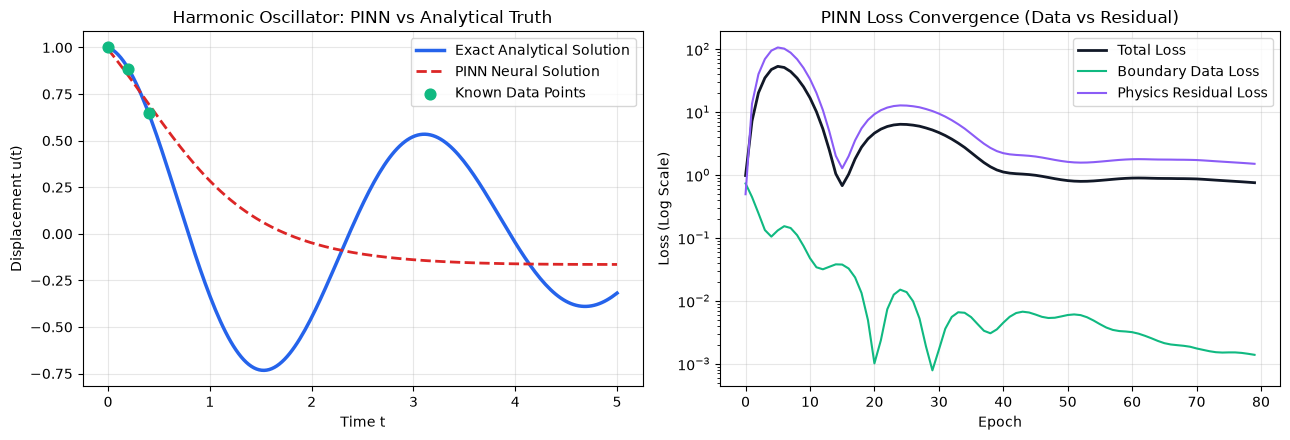

In [4]:
# 3. Predict and Compare against Exact Analytical Solution
u_pred = pinn.predict(t_domain)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(t_domain, u_exact, label='Exact Analytical Solution', color='#2563eb', lw=2.5)
ax1.plot(t_domain, u_pred, label='PINN Neural Solution', color='#dc2626', lw=2, linestyle='--')
ax1.scatter(t_data, u_data, color='#10b981', s=60, zorder=5, label='Known Data Points')
ax1.set_title('Harmonic Oscillator: PINN vs Analytical Truth')
ax1.set_xlabel('Time t')
ax1.set_ylabel('Displacement u(t)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.semilogy(history['total_loss'], label='Total Loss', color='#111827', lw=2)
ax2.semilogy(history['loss_data'], label='Boundary Data Loss', color='#10b981', lw=1.5)
ax2.semilogy(history['loss_pde'], label='Physics Residual Loss', color='#8b5cf6', lw=1.5)
ax2.set_title('PINN Loss Convergence (Data vs Residual)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss (Log Scale)')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
